# phase A — FER2013 experiments

In this notebook I compare three ways of describing a face (HOG, landmarks and PCA) and three classifiers (Logistic Regression, SVM and Random Forest). I then try two small changes to see if the best model improves.

I use the **training set** to fit models and the **validation set** to compare them. I leave the **test set** untouched until the final check. The results below must come from running the cells; no scores have been added in advance.

## 1. Imports and settings

Run this notebook from the root of the GitHub project, where the `src` folder is located. If a library is missing, install the dependencies from `requirements_phase_a.txt`.

In [2]:
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report
from features import EMOTIONS, fer_images, hog_features, landmark_features, evaluate


DATA_DIR = Path('../data/fer')
OUT_DIR = Path('../results/phase_a')
MODELS_DIR = Path('../models/phase_a')
OUT_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

# Smaller samples are useful for a first check. Use 0 for all images.
MAX_TRAIN = 1000
MAX_VALIDATION = 300


## 2. Load the FER2013 data

Each row contains an emotion label and a string of pixel values. I take roughly the same proportion from every class when using a small sample. First download the dataset using kagglehub and create the csvs.

In [4]:
# import kagglehub

#Download the dataset from Kaggle and extract it to the data directory
# path = kagglehub.dataset_download("purnisharma/fer2013")
# from pathlib import Path

# dataset_path = Path(
#     r"C:\Users\LENOVO\.cache\kagglehub\datasets\purnisharma\fer2013\versions\1"
# )

# for file in dataset_path.rglob("*"):
#     if file.is_file():
#         print(file.relative_to(dataset_path))
# print("Path to dataset files:", path)

from pathlib import Path

dataset_path = Path(
    r"C:\Users\LENOVO\.cache\kagglehub\datasets\purnisharma\fer2013\versions\1"
)

df = pd.read_csv(dataset_path / "fer2013.csv")

print(df.shape)
print(df.columns.tolist())
print(df.head())

from pathlib import Path

# Use the original FER2013 splits
train = df[df["Usage"] == "Training"][["emotion", "pixels"]].copy()
val = df[df["Usage"] == "PublicTest"][["emotion", "pixels"]].copy()
test = df[df["Usage"] == "PrivateTest"][["emotion", "pixels"]].copy()

# Save them in our project
output_dir = Path(r"C:\Users\LENOVO\Emotion_Recognition\data\fer")
output_dir.mkdir(parents=True, exist_ok=True)

train.to_csv(output_dir / "fer2013_train.csv", index=False)
val.to_csv(output_dir / "fer2013_validation.csv", index=False)
test.to_csv(output_dir / "fer2013_test.csv", index=False)

print("Training:", len(train))
print("Validation:", len(val))
print("Test:", len(test))

(35887, 3)
['emotion', 'pixels', 'Usage']
   emotion                                             pixels     Usage
0        0  70 80 82 72 58 58 60 63 54 58 60 48 89 115 121...  Training
1        0  151 150 147 155 148 133 111 140 170 174 182 15...  Training
2        2  231 212 156 164 174 138 161 173 182 200 106 38...  Training
3        4  24 32 36 30 32 23 19 20 30 41 21 22 32 34 21 1...  Training
4        6  4 0 0 0 0 0 0 0 0 0 0 0 3 15 23 28 48 50 58 84...  Training
Training: 28709
Validation: 3589
Test: 3589


Split the dataset in training and validation set.

In [5]:
def load_split(path, max_rows, seed=42):
    df = pd.read_csv(path)
    if 'emotion' not in df.columns or 'pixels' not in df.columns:
        raise ValueError(f'{path}: expected emotion and pixels columns')
    if max_rows and len(df) > max_rows:
        # Keep class proportions close to the original distribution.
        df = df.groupby('emotion', group_keys=False).sample(
            frac=max_rows / len(df), random_state=seed)
    return df.reset_index(drop=True)
print(DATA_DIR / 'fer2013_train.csv')
train = load_split(DATA_DIR / 'fer2013_train.csv', MAX_TRAIN)

val = load_split(DATA_DIR / 'fer2013_validation.csv', MAX_VALIDATION)
print('Training images:', len(train))
print('Validation images:', len(val))
train.head()

..\data\fer\fer2013_train.csv
Training images: 999
Validation images: 301


,emotion,pixels
0,0,133 103 77 54 28 30 34 30 31 51 75 53 35 32 45...
1,0,24 18 27 33 26 23 25 45 63 93 85 62 86 101 116...
2,0,228 221 215 212 215 223 242 245 244 247 249 24...
3,0,222 227 203 90 86 90 84 77 94 87 99 119 134 14...
4,0,75 101 96 44 49 70 77 88 92 87 82 75 72 62 52 ...


Test facial landmarks are loaded correclty

In [6]:
images = fer_images(train.iloc[:1])
landmarks = landmark_features(images)

print("Landmark shape:", landmarks.shape)

Landmark shape: (1, 136)


## 3. Look at the images

First I check how many examples we have for each emotion. This matters because a model can look accurate while doing badly on rare emotions.

In [7]:
def explore(df, out_dir):
    counts = df.emotion.value_counts().reindex(range(7), fill_value=0)
    counts.index = EMOTIONS
    counts.rename_axis('emotion').to_csv(out_dir / 'class_counts.csv', header=['count'])
    fig, ax = plt.subplots(figsize=(8, 4))
    counts.plot.bar(ax=ax)
    ax.set_ylabel('Number of images')
    ax.set_title('FER2013 class distribution (training data)')
    fig.tight_layout()
    fig.savefig(out_dir / 'class_distribution.png', dpi=150)
    plt.close(fig)
    ims = fer_images(df)
    means, stds = ims.mean(axis=(1, 2)), ims.std(axis=(1, 2))
    pd.DataFrame({'brightness': means, 'contrast': stds}).describe().to_csv(out_dir / 'image_statistics.csv')
    fig, axes = plt.subplots(1, 7, figsize=(14, 2.5))
    for label, ax in enumerate(axes):
        pos = np.flatnonzero(df.emotion.to_numpy() == label)
        if len(pos): ax.imshow(ims[pos[0]], cmap='gray', vmin=0, vmax=255)
        ax.set_title(EMOTIONS[label]); ax.axis('off')
    fig.tight_layout()
    fig.savefig(out_dir / 'sample_images.png', dpi=150)
    plt.close(fig)


explore(train, OUT_DIR)
train.emotion.map(dict(enumerate(EMOTIONS))).value_counts()


emotion
Happy       251
Neutral     173
Sad         168
Fear        143
Angry       139
Surprise    110
Disgust      15
Name: count, dtype: int64

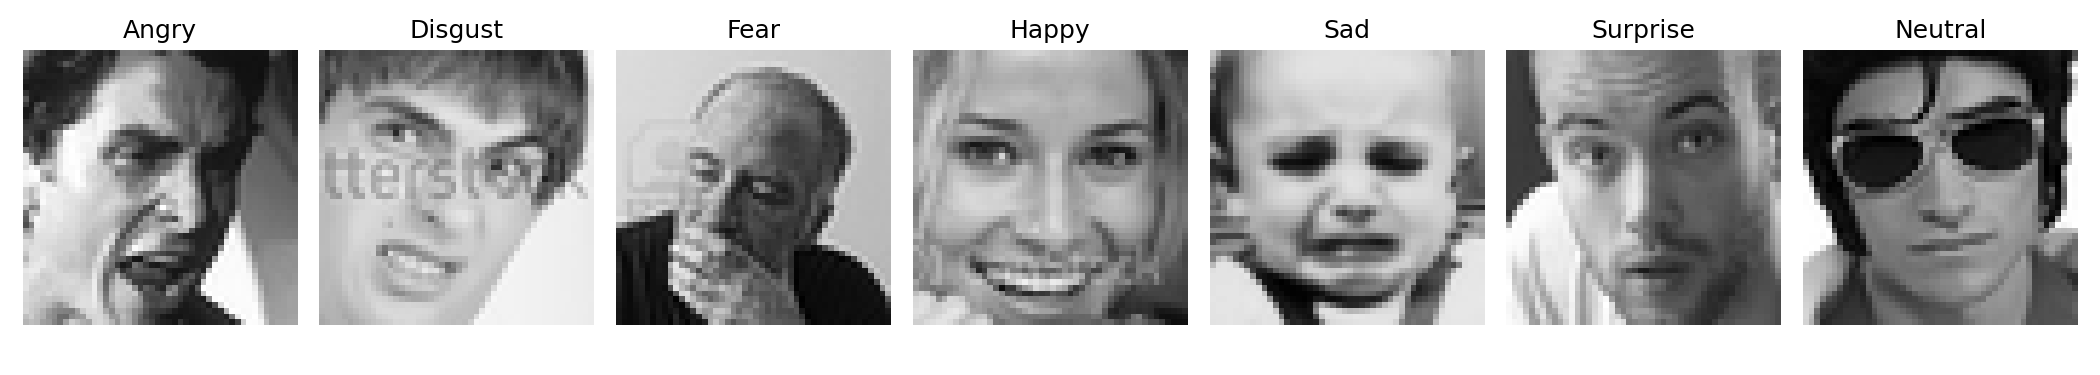

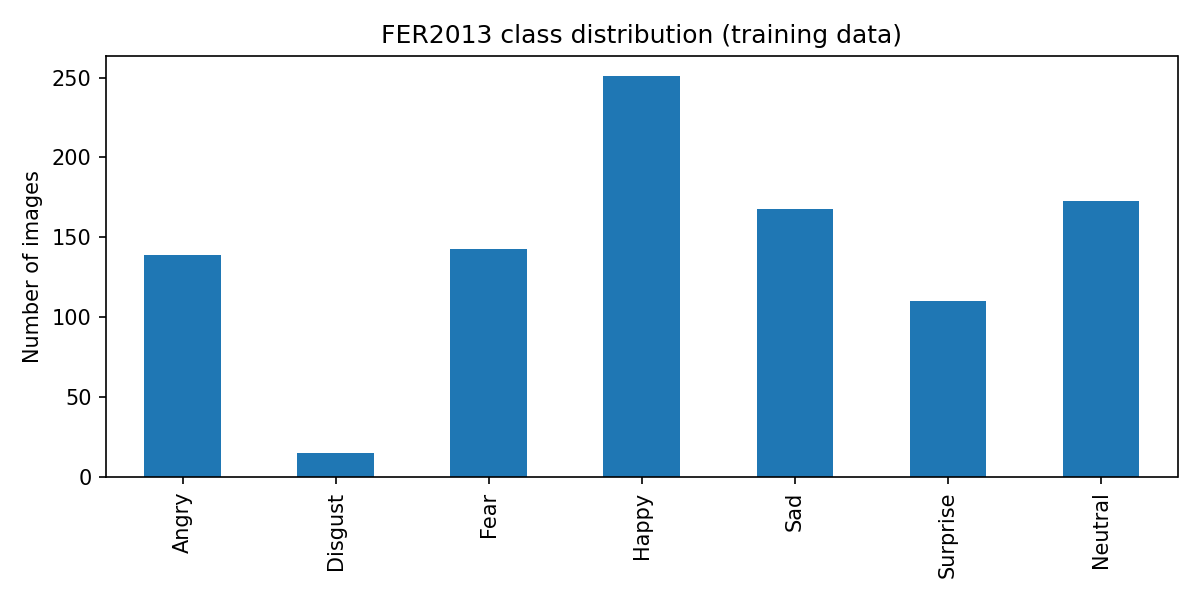

In [70]:
from IPython.display import display, Image
display(Image(filename=str(OUT_DIR / 'sample_images.png')))
display(Image(filename=str(OUT_DIR / 'class_distribution.png')))


## 4. Feature extraction

- **HOG** captures edges and changes in shape.
- **Landmarks** use 68 points around the eyes, mouth, nose and jaw.
- **PCA** reduces the number of pixel values while keeping the main patterns.

PCA is fitted on the training images only, so the validation data does not influence the extracted components.

In [8]:
def features_for(name, train_imgs, val_imgs, test_imgs, model_dir, include_test=False):
    if name == 'PCA':
        transformer = make_pipeline(StandardScaler(), PCA(n_components=min(100, len(train_imgs) - 1, train_imgs.shape[1] * train_imgs.shape[2]), svd_solver='randomized', random_state=42))
        # Use 100 components for speed; PCA is fitted only to training data.
        x_train = transformer.fit_transform(train_imgs.reshape(len(train_imgs), -1))
        x_val = transformer.transform(val_imgs.reshape(len(val_imgs), -1))
        x_test = transformer.transform(test_imgs.reshape(len(test_imgs), -1)) if include_test else None
        return x_train, x_val, x_test, transformer
    if name == 'HOG': func = hog_features
    else: func = landmark_features
    return func(train_imgs), func(val_imgs), func(test_imgs) if include_test else None, None


y_train = train.emotion.to_numpy()
y_val = val.emotion.to_numpy()
train_imgs = fer_images(train)
val_imgs = fer_images(val)


## 5. Define the classifiers

I use Logistic Regression, an RBF SVM and a Random Forest. Scaling is included for Logistic Regression and SVM because their results depend on feature magnitude.

In [9]:
def make_model(kind, class_weight=None, c=1.0):
    if kind == 'LR':
        return make_pipeline(StandardScaler(), LogisticRegression(C=c, max_iter=2000,
                                    class_weight=class_weight, random_state=42))
    if kind == 'SVM':
        return make_pipeline(StandardScaler(), SVC(C=c, kernel='rbf', gamma='scale',
                                    class_weight=class_weight, cache_size=500))
    return RandomForestClassifier(n_estimators=150, max_depth=None,
                                  class_weight=class_weight, random_state=42, n_jobs=-1)


## 6. Train the nine baseline combinations

The same validation data is used for every combination. I compare **accuracy**, **balanced accuracy** and **macro F1**, with macro F1 useful when some emotions have fewer examples. Landmark extraction may take a while.

dlib version: 19.24.2
Current directory: c:\Users\LENOVO\Emotion_Recognition\src
Landmark shape: (1, 136)
Extracting: HOG
Training: HOG_LR


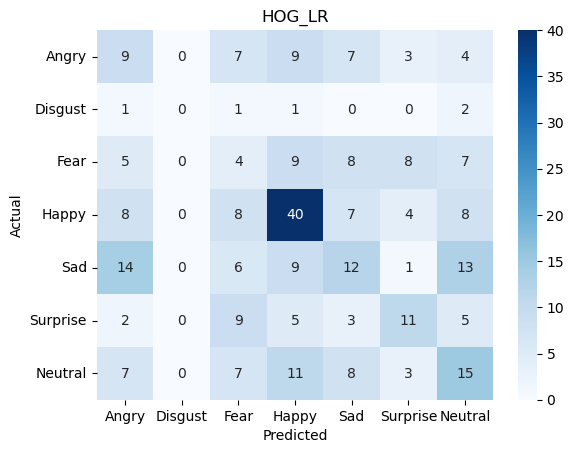

Training: HOG_SVM


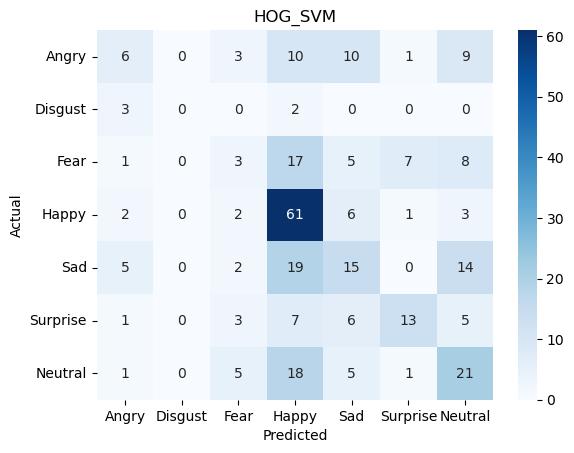

Training: HOG_RF


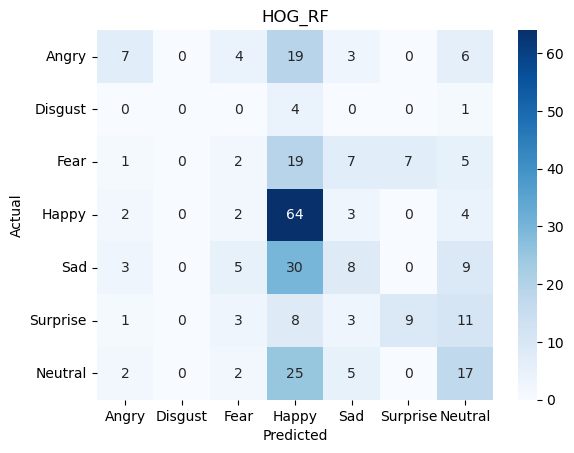

Extracting: Landmarks
Training: Landmarks_LR


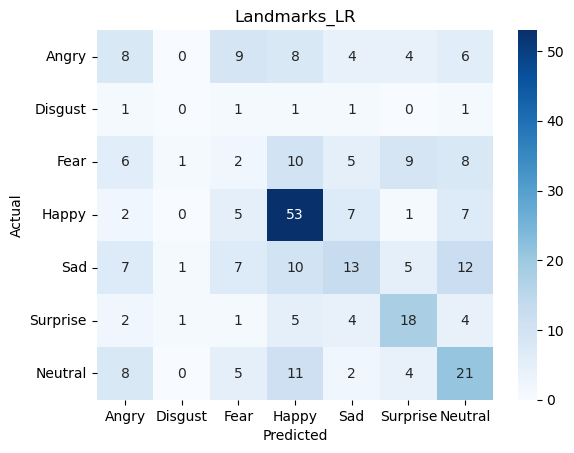

Training: Landmarks_SVM


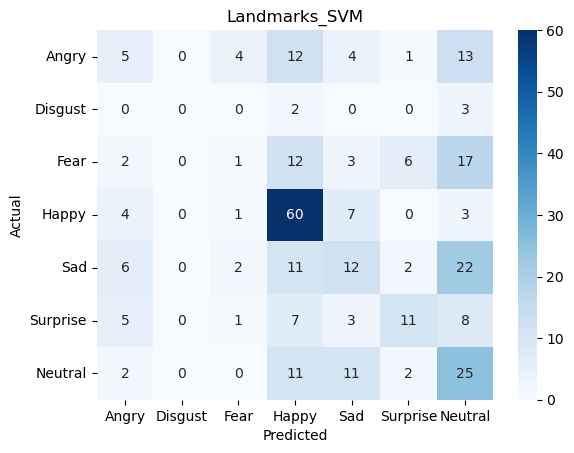

Training: Landmarks_RF


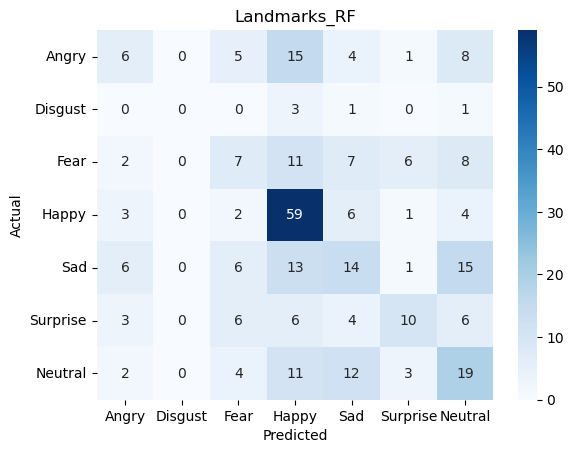

Extracting: PCA
Training: PCA_LR


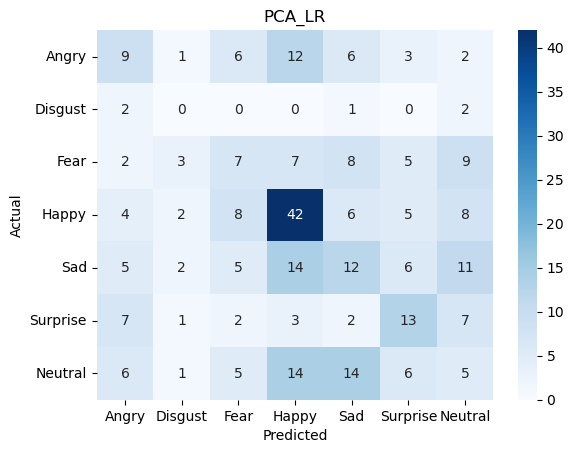

Training: PCA_SVM


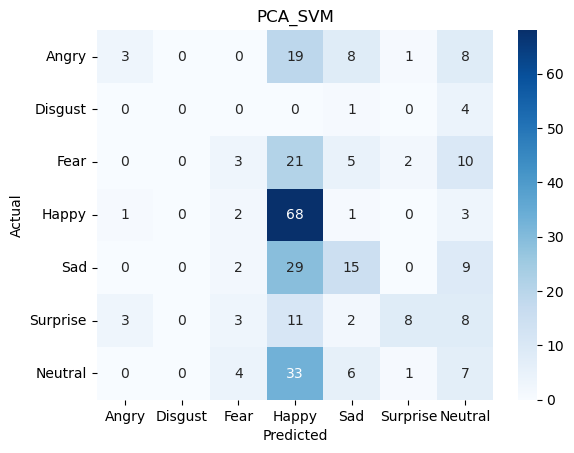

Training: PCA_RF


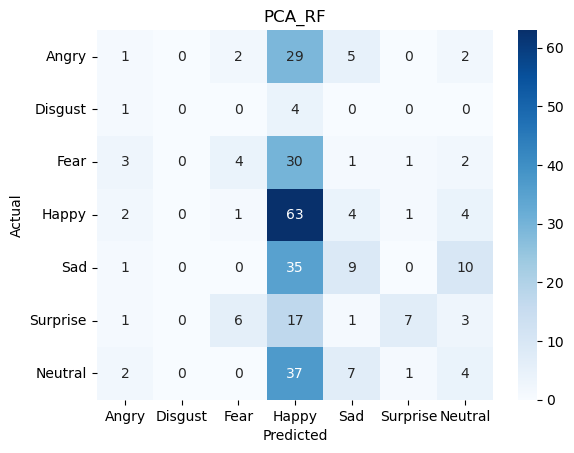

,model,acc,bal_acc,macro_f1
3,Landmarks_LR,0.382060,0.303284,0.289921
1,HOG_SVM,0.395349,0.299467,0.287585
5,Landmarks_RF,0.382060,0.289150,0.281044
4,Landmarks_SVM,0.378738,0.282180,0.260145
2,HOG_RF,0.355482,0.259647,0.245325
0,HOG_LR,0.302326,0.241178,0.239353
6,PCA_LR,0.292359,0.235593,0.232518
7,PCA_SVM,0.345515,0.242188,0.224826
8,PCA_RF,0.292359,0.200753,0.179788


In [11]:
import dlib
import importlib
import features
import dlib
from pathlib import Path

importlib.reload(features)

evaluate = features.evaluate
landmark_features = features.landmark_features

print("dlib version:", dlib.__version__)
print("Current directory:", Path.cwd())

images = fer_images(train.iloc[:1])

landmarks = landmark_features(images)

print("Landmark shape:", landmarks.shape)

rows = []
fitted = {}
stored_features = {}
for feature_name in ['HOG', 'Landmarks', 'PCA']:
    print('Extracting:', feature_name)
    try:
        Xtr, Xv, _, transformer = features_for(feature_name, train_imgs, val_imgs, None, MODELS_DIR)
    except (ImportError, FileNotFoundError, RuntimeError) as exc:
        print('Skipped', feature_name, 'because:', exc)
        continue
    stored_features[feature_name] = (Xtr, Xv, transformer)
    for model_name in ['LR', 'SVM', 'RF']:
        name = f'{feature_name}_{model_name}'
        print('Training:', name)
        model = make_model(model_name)
        model.fit(Xtr, y_train)
        predicted = model.predict(Xv)
        result = evaluate(y_val, predicted, name)
        result.update({'feature': feature_name, 'classifier': model_name})
        rows.append(result)
        fitted[name] = model
        joblib.dump({'model': model, 'feature': feature_name, 'transformer': transformer}, MODELS_DIR / f'{name}.pkl')
if not rows:
    raise RuntimeError('No experiments completed. Check your dependencies and data paths.')
results = pd.DataFrame(rows).sort_values('macro_f1', ascending=False)
results.to_csv(OUT_DIR / 'baseline_validation.csv', index=False)
results[['model', 'acc', 'bal_acc', 'macro_f1']]


### Baseline Results

I compared three classifiers (Logistic Regression, SVM and Random Forest) using HOG, facial landmarks and PCA features.

Landmarks with Logistic Regression achieved the highest macro F1 score (0.290), while HOG with SVM had the highest accuracy (39.5%). The difference between their macro F1 scores was very small.

Overall, landmark and HOG features performed better than PCA in these experiments. PCA with Random Forest gave the lowest macro F1 score (0.180).

The results are still relatively low, showing that recognizing different emotions from facial images is challenging.

## 7. Creative challenge — two changes

I take the strongest baseline based on validation macro F1, then test two changes:

1. **Class weights:** give rare emotions more importance.
2. **Parameter change:** adjust model regularisation (or tree depth for Random Forest).

I compare the original model, each change on its own, and both together. 

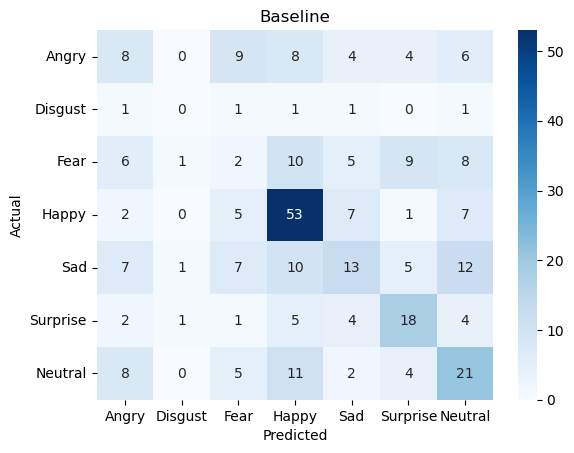

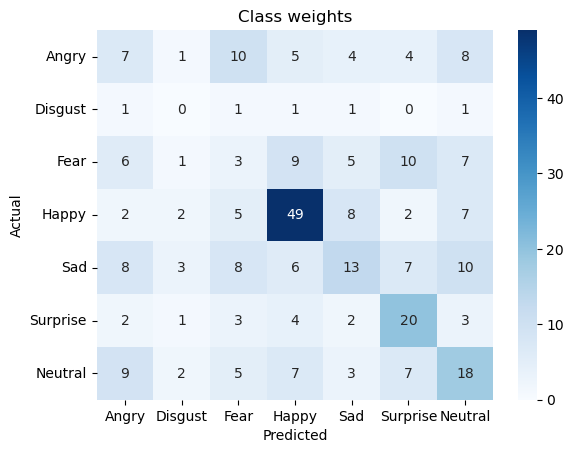

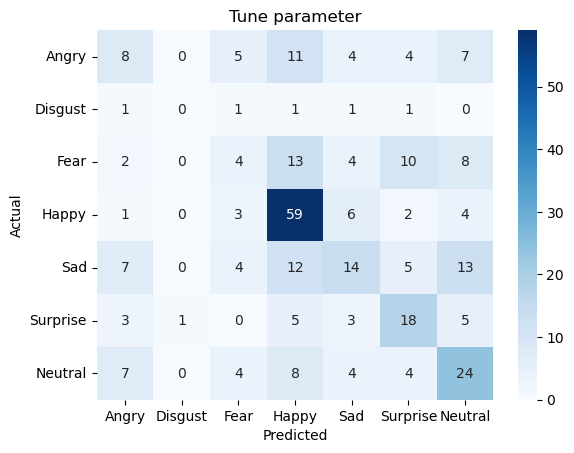

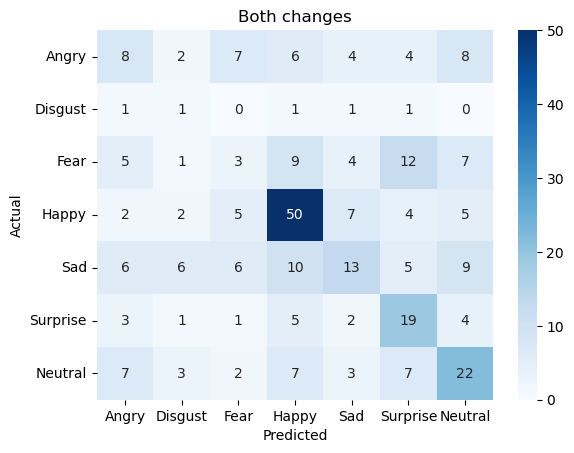

Best baseline: Landmarks_LR
Best variation: Tune parameter


,change,acc,bal_acc,macro_f1
0,Baseline,0.382060,0.303284,0.289921
1,Class weights,0.365449,0.295246,0.285072
2,Tune parameter,0.421927,0.332682,0.313942
3,Both changes,0.385382,0.336508,0.310058


In [12]:
best = results.iloc[0]
feat, clf = best['feature'], best['classifier']
Xtr, Xv, transformer = stored_features[feat]
variations = [('Baseline', None, 1.0), ('Class weights', 'balanced', 1.0),
              ('Tune parameter', None, 0.3), ('Both changes', 'balanced', 0.3)]
ablation = []
best_creative, best_score, best_change = None, -1, None
for label, weight, c in variations:
    if clf == 'RF':
        model = make_model('RF', weight)
        if c != 1.0:
            model.set_params(max_depth=15)
    else:
        model = make_model(clf, weight, c)
    model.fit(Xtr, y_train)
    predicted = model.predict(Xv)
    result = evaluate(y_val, predicted, label)
    result['change'] = label
    ablation.append(result)
    if result['macro_f1'] > best_score:
        best_creative, best_score, best_change = model, result['macro_f1'], label
ablation_table = pd.DataFrame(ablation)
ablation_table.to_csv(OUT_DIR / 'creative_ablation_validation.csv', index=False)
joblib.dump({'model': best_creative, 'feature': feat, 'transformer': transformer,
             'labels': EMOTIONS}, MODELS_DIR / 'final_selected_model.pkl')
print('Best baseline:', best['model'])
print('Best variation:', best_change)
ablation_table[['change', 'acc', 'bal_acc', 'macro_f1',]]


### Creative Challenge Results

I used Landmarks with Logistic Regression as my baseline because it had the highest macro F1 score among the nine models.

I tested two changes: adding class weights and tuning the regularization parameter.

Parameter tuning gave the best results, improving accuracy from 38.2% to 42.2% and macro F1 from 0.290 to 0.314.

Adding class weights alone did not improve the results. Combining both changes improved balanced accuracy, but the macro F1 was slightly lower than with parameter tuning alone.

Based on these results, I selected **Landmarks with Logistic Regression and parameter tuning** as my final model.

## 8. Final test 

**Do not run during model selection.** Once the model and settings are final, change `RUN_FINAL_TEST` to `True` and run this cell one time. Do not tune the model based on the test score. Note down the sample sizes and settings you used for your final experiment.

Selected features: Landmarks
Selected model: Pipeline(steps=[('standardscaler', StandardScaler()),
                ('logisticregression',
                 LogisticRegression(C=0.3, max_iter=2000, random_state=42))])


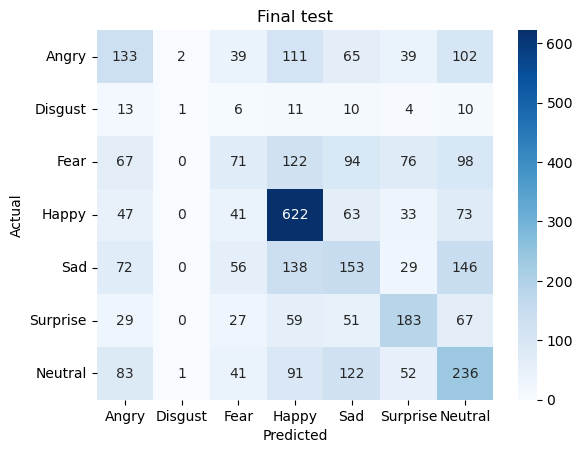

{'model': 'Final test', 'acc': 0.38980217330732797, 'bal_acc': 0.3150894265437683, 'macro_f1': 0.3084168594777162}
              precision    recall  f1-score   support

       Angry       0.30      0.27      0.28       491
     Disgust       0.25      0.02      0.03        55
        Fear       0.25      0.13      0.18       528
       Happy       0.54      0.71      0.61       879
         Sad       0.27      0.26      0.27       594
    Surprise       0.44      0.44      0.44       416
     Neutral       0.32      0.38      0.35       626

    accuracy                           0.39      3589
   macro avg       0.34      0.32      0.31      3589
weighted avg       0.37      0.39      0.37      3589



In [13]:
print("Selected features:", feat)
print("Selected model:", best_creative)
RUN_FINAL_TEST = True
if RUN_FINAL_TEST:
    test = load_split(DATA_DIR / 'fer2013_test.csv', 0)
    test_imgs = fer_images(test)
    if feat == 'PCA':
        Xtest = transformer.transform(test_imgs.reshape(len(test_imgs), -1))
    elif feat == 'HOG':
        Xtest = hog_features(test_imgs)
    else:
        Xtest = landmark_features(test_imgs)
    test_pred = best_creative.predict(Xtest)
    test_result = evaluate(test.emotion.to_numpy(), test_pred, 'Final test')
    print(test_result)
    report = classification_report(test.emotion.to_numpy(), test_pred,
                                  labels=list(range(7)), target_names=EMOTIONS,
                                  zero_division=0)
    print(report)
    (OUT_DIR / 'classification_report_test.txt').write_text(report)
else:
    print('Final test skipped. Set RUN_FINAL_TEST = True once model selection is finished.')


### Final Test Results

I tested the selected Landmarks + Logistic Regression model on the FER2013 test set, which contains 3,589 images.

The model achieved 39.0% accuracy, 31.5% balanced accuracy and a macro F1 score of 0.308. These results were slightly lower than the validation results.

The model performed best on Happy (F1 = 0.61) and Surprise (F1 = 0.44). It struggled the most with Disgust (F1 = 0.03) and Fear (F1 = 0.18).

Overall, the model recognizes some emotions better than others, but its performance is still limited. The small training sample and the imbalance between emotion classes may have affected the results.

In [15]:
saved = joblib.load(MODELS_DIR / "final_selected_model.pkl")

print(saved["feature"])
print(saved["model"].predict(Xtest[:5]))

Landmarks
[6 4 4 2 0]


### Error Analysis — Misclassified Images

To better understand the mistakes made by my final model, I looked at some test images where the predicted emotion was different from the actual emotion.